# Figure 3 e–h — barrages and the background, non-overlapping windows

The four panels of `fig3_background_repro.py` (`NONOVERLAP=1`), each drawn as its own figure.

- **e** d2 by barrage-rate sextile, full window (grey) and ripples + barrages excised (blue); 12 sessions, non-overlapping 30 s NREM windows, mean ± SEM over sessions; legend: sextile-mean r and the per-session Spearman signed-rank test for each arm.
- **f** branching ratio around barrage starts, ripples + barrages excised, example PPP7_day7 (`fig3f_psth_excised.py`), ± SEM over barrages; inset: per-file change on non-overlapping windows, barrage vs shuffle, paired Wilcoxon and a mixed model.
- **g** (right) background d2, baseline vs barrage disruption (CCK silencing), session means, 7 sessions, paired Wilcoxon; the left half is the example from `Fig3_ADG_from_submitted`.
- **h** ISI entropy by barrage-rate equal-width bin, non-overlapping windows, mean ± SEM; mixed model (ISI entropy ~ rate + animal, random intercept and slope per session).

In [1]:
# Data: ../csv/Fig3_EFGH_barrage_bgd2/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'Fig3_EFGH_barrage_bgd2'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import final_figs as F                     # print styles, saving, stars

saved figure_output\Fig3\Fig3_E_d2_by_barrage_rate_bgd2.svg / .png


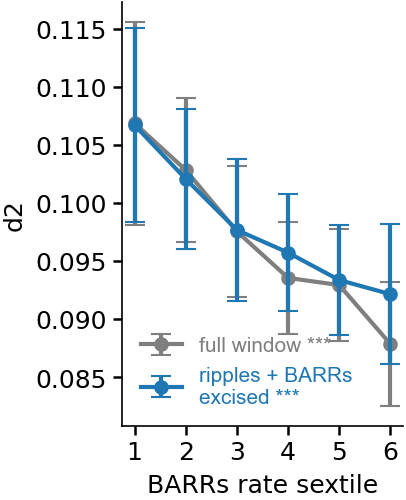

saved figure_output\Fig3\Fig3_G_cck_silencing_bgd2.svg / .png


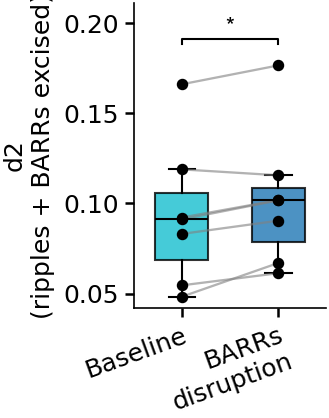

saved figure_output\Fig3\Fig3_H_isi_entropy_by_barrage_rate.svg / .png


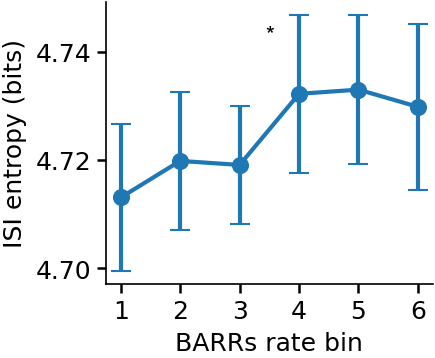

saved figure_output\Fig3\Fig3_F_br_around_barrages_bgd2.svg / .png


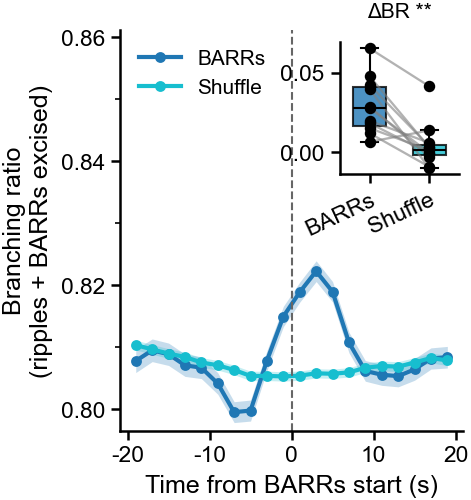

f inset: BARRs vs shuffle, two-sided paired Wilcoxon signed-rank p = 0.002, paired LMM p = 0.00076; n = 11 sessions


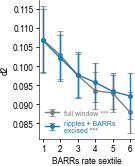

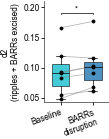

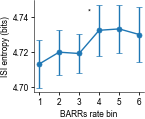

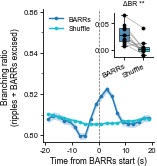

In [2]:
import importlib
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# e, g (box) and h: the non-overlapping background-d2 composite (fig3_background_repro.py, NONOVERLAP=1 ->
# reports/revision_figs/fig3_background_repro_non-overlapping), drawn by its own main(), with its 1 x 4 axes
# routed into four print-size figures.
os.environ["NONOVERLAP"] = "1"                         # read at import
os.environ.pop("BINS", None)                           # its default: e rank sextiles, h equal-width bins
import fig3_background_repro_drawing as M   # fig3_background_repro.py's figure code (copied)
M = importlib.reload(M)
assert M.NONOVERLAP
M.LOG = str(CSV)                                # its tables: this notebook's csv folder

SIZE = {"e": (36, 44), "f": (20, 20), "g": (29.5, 37), "h": (38.5, 32)}   # mm; h wide and flat for smaller-looking SEM bars; f's box is redrawn as f's inset
figs = {k: plt.figure(figsize=(w * F.MM, h * F.MM), layout="constrained") for k, (w, h) in SIZE.items()}
axes = [figs[k].add_subplot() for k in "efgh"]


class _Sink:                                           # stands in for the producer's 1 x 4 figure: nothing saved
    def text(self, *a, **k): pass
    def tight_layout(self, *a, **k): pass
    def savefig(self, *a, **k): pass


# ---- data (../csv) ----
# what fig3_background_repro.main() computed (non-overlapping windows), then drawn by its own figure code
import types
_e, _rho, _es = read_csv('fig3e_sextiles.csv'), read_csv('fig3e_session_rho.csv'), read_csv('fig3e_stats.csv').set_index('arm')
res = {lab: (_e[_e.arm == lab].set_index('tile')['mean'], _e[_e.arm == lab].set_index('tile')['sem'],
             types.SimpleNamespace(rvalue=_es.loc[lab, 'r'], pvalue=_es.loc[lab, 'p']), int(_es.loc[lab, 'n']),
             _rho[_rho.arm == lab].set_index('session')['rho'], _es.loc[lab, 'prho'])
       for lab in ('full window', 'background')}
_s = read_csv('fig3_main_scalars.csv').iloc[0]
_pf_box = read_csv('fig3f_box_sessions.csv', index_col='animal_day')
_G = read_csv('fig3g_sessions.csv', index_col='animal_day')
_subplots = M.plt.subplots
M.plt.subplots = lambda *a, **k: (_Sink(), axes)
try:
    M.draw_main(res, _pf_box, _s.p_f, int((_pf_box.Barrage > _pf_box.Barrage_Shuffle).sum()),
                types.SimpleNamespace(pvalue=_s.wf_p), _G,
                int((_G.postsleep > _G.presleep).sum()), types.SimpleNamespace(pvalue=_s.wg_p), read_csv('fig3h_bins.csv'),
                _s.r_h, _s.p_h, "")
finally:
    M.plt.subplots = _subplots
S1 = pd.DataFrame([dict(panel="f_sessions", n=len(_pf_box), p=_s.wf_p,              # the session-level tests of f and g
                        n_dir=int((_pf_box.Barrage > _pf_box.Barrage_Shuffle).sum())),
                   dict(panel="g_background_sessions", n=len(_G), p=_s.wg_p, n_dir=int((_G.postsleep > _G.presleep).sum()))])
# ---- the same from the recordings, with analysis_scripts/: ----
# stored = M.OUT_CSV
# M.OUT_CSV = os.path.join(tempfile.mkdtemp(), os.path.basename(stored))
# _subplots = M.plt.subplots
# M.plt.subplots = lambda *a, **k: (_Sink(), axes)
# try:
#     M.main()
# finally:
#     M.plt.subplots = _subplots
# S0, S1 = pd.read_csv(stored), pd.read_csv(M.OUT_CSV)
# num = S0.select_dtypes("number").columns
# same = S0.shape == S1.shape and np.allclose(S0[num].to_numpy(float), S1[num].to_numpy(float), rtol=1e-3, equal_nan=True)   # LMM p: optimiser noise ~1e-4
# print(f"statistics identical to the stored {os.path.basename(stored)}: {same}")
ST = S1.set_index("panel")
for ax in axes:                                        # the axes were made before main() set its style (no top /
    for sp in ("top", "right"):                        # right spines)
        ax.spines[sp].set_visible(False)
star = lambda p: "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "n.s."     # noqa: E731
FONT = 0.6                                             # the producer draws at 10 pt -> 6 pt


def bracket(ax, text, frac=0.06):
    lo, hi = ax.get_ylim(); y = hi + frac * (hi - lo)
    ax.plot([0, 0, 1, 1], [y - 0.02 * (hi - lo), y, y, y - 0.02 * (hi - lo)], color="k", lw=1.0, clip_on=False)
    ax.text(0.5, y + 0.01 * (hi - lo), text, ha="center", va="bottom", fontsize=9)
    ax.set_ylim(lo, hi + 0.2 * (hi - lo))


# ---- e: d2 by barrage-rate sextile, full window (grey) and ripples + barrages excised (blue)
ax = axes[0]
ax.set_title("", loc="left")                        # the producer's titles are left titles
ax.set_ylabel("d2"); ax.set_xlabel("BARRs rate sextile")          # final figures: "d2" only
st_e = list(ax.texts)                                  # "12/12 ↓ ***", "11/12 ↓ ***": the two arms, in drawing order
hh, ll = ax.get_legend_handles_labels()
for h_, l_ in zip(hh, ll):
    h_.set_label(l_.replace("ripples + barrages excised", "ripples + BARRs\nexcised"))   # "BARRs" on the figure; two lines
ax.legend(frameon=False, fontsize=8, loc="lower left")
F.shrink(figs["e"], font=FONT)
for t in ax.get_legend().get_texts():
    t.set_color("tab:blue" if "excised" in t.get_text() else "#7f7f7f")
# the stars of each arm move into its legend entry
F.settle(figs["e"])
for t, s_ in zip(ax.get_legend().get_texts(), st_e):  # formal: the stars beside the legend entry ("full window ***")
    t.set_text(f"{t.get_text()} {s_.get_text().split()[-1]}")
    s_.remove()
F.show(F.save(figs["e"], "Fig3_E_d2_by_barrage_rate_bgd2"))

# ---- g (box): background d2, baseline vs barrage disruption (CCK silencing), session means
ax = axes[2]
ax.set_title("", loc="left")                        # the producer's titles are left titles
ax.set_ylabel("d2\n(ripples + BARRs excised)")                  # labelled by what is excised, not "background d2"
ax.set_xticklabels(["Baseline", "BARRs\ndisruption"], rotation=20, ha="right", rotation_mode="anchor")   # tilted: no collision
g = ST.loc["g_background_sessions"]
bracket(ax, f"{int(g.n_dir)}/{int(g.n)} ↑ {star(g.p)}")
F.shrink(figs["g"], font=FONT)
F.settle(figs["g"])
F.drop_counts(figs["g"])
F.show(F.save(figs["g"], "Fig3_G_cck_silencing_bgd2"))

# ---- h: ISI entropy by barrage-rate equal-width bin; the mixed model's star
ax = axes[3]
ax.set_title("", loc="left")
ax.set_xlabel("BARRs rate bin")
L = pd.read_csv(os.path.join(M.LOG, "fig3h_entropy_diagnostics_lmm.csv"))
L = L[L.panel.str.startswith("h") & (L.model == "C(animal) + (1 + rate|session)")].iloc[0]
ax.text(0.5, 0.92, star(L.p), transform=ax.transAxes, ha="center", va="top", fontsize=9)
F.shrink(figs["h"], font=FONT)
F.show(F.save(figs["h"], "Fig3_H_isi_entropy_by_barrage_rate"))
plt.close(figs["f"])                                   # the producer's f box: redrawn below as f's inset

# ---- f: branching ratio around barrage starts, ripples + barrages excised, example animal PPP7_day7, from
# fig3f_psth_excised.py; inset: the non-overlapping per-session change (fig3_background_repro.panel_f,
# *_br_changes_non_overlap.pkl)
# ---- data (../csv) ----
CURVES = CSV / "fig3f_psth_curves_PPP7_day7.csv"   # fig3f_psth_excised.py (SESS=PPP7_day7)
# ---- the same from the recordings, with analysis_scripts/: ----
# CURVES = os.path.join(F.REPO, "data", "revision", "log", "fig3f_psth_curves_PPP7_day7.csv")
# if not os.path.exists(CURVES):
#     import subprocess
#     subprocess.run([sys.executable, os.path.join(F.REV, "fig3f_psth_excised.py")],
#                    env={**os.environ, "SESS": "PPP7_day7"}, check=True)          # reads W: read-only, ~3 min
c = pd.read_csv(CURVES)
c = c[c.arm == "excised"].sort_values("lag_s")
# ---- data (../csv) ----
pf = read_csv('fig3f_inset_sessions.csv', index_col='animal_day')   # M.panel_f(nonoverlap_files=True): per-session dBR
p_lmm = read_csv('fig3f_inset_lmm.csv').p_lmm[0]
# ---- the same from the recordings, with analysis_scripts/: ----
# pf, p_lmm, diff = M.panel_f(nonoverlap_files=True)
fsess = ST.loc["f_sessions"]
F.native_style()
fig, ax = plt.subplots(figsize=(41.5 * F.MM, 44 * F.MM), layout="constrained")
for key, ek, col, lab in (("br_barrage", "sem_barrage", "tab:blue", "BARRs"), ("br_shuffle", "sem_shuffle", "tab:cyan", "Shuffle")):
    ax.plot(c.lag_s, c[key], "-o", ms=3.5, lw=2, color=col, label=lab)      # at 10 pt
    ax.fill_between(c.lag_s, c[key] - c[ek], c[key] + c[ek], color=col, alpha=0.25, lw=0)
ax.axvline(0, ls="--", lw=1, color="0.4")
lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 1.25 * (hi - lo))   # headroom for the inset
ax.set_xticks([-20, -10, 0, 10, 20])
ax.set_xlabel("Time from BARRs start (s)"); ax.set_ylabel("Branching ratio\n(ripples + BARRs excised)")
ax.legend(frameon=False, loc="upper left")              # left of the inset, above the curve
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ins = ax.inset_axes([0.64, 0.64, 0.35, 0.33])           # the producer's box
for i, col_ in enumerate(("Barrage", "Barrage_Shuffle")):
    ins.boxplot(pf[col_], positions=[i], widths=0.55, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor=("tab:blue", "tab:cyan")[i], alpha=0.8), medianprops=dict(color="k"))
for _, r in pf.iterrows():
    ins.plot([0, 1], [r.Barrage, r.Barrage_Shuffle], "-", color="gray", alpha=0.6, lw=1.1)
    ins.scatter([0, 1], [r.Barrage, r.Barrage_Shuffle], s=14, color="k", zorder=3)
ins.set_xticks([0, 1]); ins.set_xticklabels(["BARRs", "Shuffle"], fontsize=9, rotation=25, ha="right", rotation_mode="anchor")   # tilted: they collide flat at print size
ins.tick_params(axis="y", labelsize=9)
ins.set_title(f"ΔBR  {int(fsess.n_dir)}/{int(fsess.n)} ↑ {star(fsess.p)}", fontsize=9)
for sp in ("top", "right"):
    ins.spines[sp].set_visible(False)
F.shrink(fig)
F.sparse_yticks(ax)
F.settle(fig)
F.drop_counts(fig)
F.show(F.save(fig, "Fig3_F_br_around_barrages_bgd2"))
print(f"f inset: BARRs vs shuffle, two-sided paired Wilcoxon signed-rank p = {fsess.p:.2g}, paired LMM p = {p_lmm:.2g}; "
      f"n = {int(fsess.n)} sessions")